In [8]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Load NIFTY-50 dataset
data = pd.read_csv("NIFTY50.csv")

# Sort data by date
data = data.sort_values("Date")

# Get closing prices
prices = data["Close"].values

In [9]:
# Use previous 5 days to predict the next day
X, y = [], []

# Create input and output samples
for i in range(5, len(prices)):
    X.append(prices[i-5:i])
    y.append(prices[i])

# Convert lists into arrays
X = np.array(X)
y = np.array(y)

In [10]:
# Split data chronologically (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Create and train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test values
predictions = model.predict(X_test)

In [11]:
# Calculate prediction error
error = mean_absolute_error(y_test, predictions)
print("Mean Absolute Error:", error)

# Predict the next day's closing price
next_day = model.predict([prices[-5:]])

print("Predicted NIFTY-50 Closing Price:", next_day[0])

Mean Absolute Error: 47.752349172187365
Predicted NIFTY-50 Closing Price: 1103.4669299000182


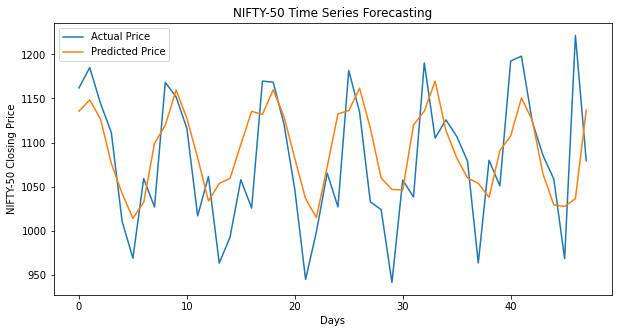

In [12]:
# Plot actual and predicted closing prices
plt.figure(figsize=(10, 5))

plt.plot(y_test, label="Actual Price")
plt.plot(predictions, label="Predicted Price")

# Add graph labels and title
plt.xlabel("Days")
plt.ylabel("NIFTY-50 Closing Price")
plt.title("NIFTY-50 Time Series Forecasting")

# Display legend and graph
plt.legend()
plt.show()